<a href="https://colab.research.google.com/github/rgonzalezp-ucsc/Ciencia-de-Datos_UCSC_Rodrigo_G/blob/main/S4_Notebook_CDD_GONZALEZ_RODRIGO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 4 — Minería de datos, validación y volumen
**Ciencia de Datos · Semana 4 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 2) · RA3 (transversal) |
| **Duración estimada** | 1,25 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `conjunto_explorado_RG.csv`, producido en la semana 3 |
| **Producto** | Este cuaderno completo — **es la Entrega 3** |
| **Estudiante** | _Rodrigo I. González Panes_ |

---

Esta semana pasas de **describir** a **descubrir**. Las tres técnicas de minería encuentran estructura que no se ve a simple vista; la validación decide si ese hallazgo se sostiene.

Las partes 1, 2 y 5 son **guiadas**, con los datos que trae el curso. Las partes 3 y 4 las aplicas sobre **tu propio conjunto**.

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = '/content/'
SEMILLA = 20264
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

# En Google Colab, mlxtend ya viene instalado. En local:
# !pip install mlxtend scikit-learn
print('Listo')

Listo


---
## Parte 1 · Reglas de asociación

Una regla de asociación tiene la forma **A → B**: «quien lleva A, tiende a llevar B». Se miden con tres números, y confundirlos es el error clásico del tema.

| Métrica | Qué mide | Trampa |
|---|---|---|
| **Soporte** | Qué fracción de las canastas contiene A y B juntos | Una regla con soporte mínimo puede ser una casualidad |
| **Confianza** | De quienes llevan A, qué fracción lleva también B | **Sube sola si B es muy frecuente** |
| **Lift** | Cuántas veces más probable es B dado A, comparado con el azar | > 1 asociación real · = 1 independencia · < 1 se repelen |

In [60]:
df = pd.read_csv(RUTA + 'S4_Dataset_Transacciones_CDD.csv', sep=';')
print('Líneas:', len(df), '· Transacciones:', df['transaccion_id'].nunique(),
      '· Productos:', df['producto'].nunique())
df.head()

Líneas: 21494 · Transacciones: 4000 · Productos: 21


,transaccion_id,fecha,tienda,producto
0,T00001,2025-03-02,Norte,pan
1,T00001,2025-03-02,Norte,vino
2,T00002,2025-06-22,Oriente,azucar
3,T00002,2025-06-22,Oriente,cafe
4,T00002,2025-06-22,Oriente,fideos


Se cargó el conjunto de datos utilizando Pandas, identificando 21.494 registros, 4.000 transacciones y 21 productos diferentes. Esta estructura permite analizar qué productos suelen comprarse juntos mediante reglas de asociación.

### 1.1 De lista larga a matriz de canasta

Los algoritmos necesitan una matriz booleana: una fila por transacción, una columna por producto.

In [61]:
cesta = (df.assign(v=1)
           .pivot_table(index='transaccion_id', columns='producto',
                        values='v', fill_value=0)
           .astype(bool))
print('Matriz:', cesta.shape)
cesta.iloc[:5, :6]

Matriz: (4000, 21)


producto,arroz,azucar,cafe,cerveza,detergente,fideos
transaccion_id,,,,,,
T00001,False,False,False,False,False,False
T00002,False,True,True,False,False,True
T00003,False,True,False,True,False,False
T00004,True,False,False,False,False,False
T00005,False,True,False,False,False,False


Se transformaron los registros en una matriz booleana de 4.000 transacciones y 21 productos. Esta estructura permite identificar la presencia o ausencia de cada producto en las compras y sirve como base para descubrir asociaciones entre ellos.

In [62]:
# Frecuencia de cada producto: fíjate en los dos primeros
frecuencias = cesta.mean().sort_values(ascending=False)
frecuencias.head(8).round(3)

,0
producto,
pan,0.622
leche,0.566
palta,0.462
azucar,0.321
salsa de tomate,0.304
huevos,0.294
jamon,0.240
arroz,0.238


El análisis de frecuencia muestra que el pan (62,2 %) y la leche (56,6 %) son los productos más presentes en las compras. Estos resultados permiten reconocer los productos más populares y sirven como referencia para identificar posibles asociaciones entre ellos.

### 1.2 Extraer las reglas

In [63]:
from mlxtend.frequent_patterns import apriori, association_rules

frecuentes = apriori(cesta, min_support=0.05, use_colnames=True)
reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.10)

# nos quedamos con las reglas de un producto a un producto, más fáciles de leer
reglas = reglas[(reglas['antecedents'].str.len() == 1) &
                (reglas['consequents'].str.len() == 1)].copy()
reglas['regla'] = (reglas['antecedents'].map(lambda s: list(s)[0]) + ' → ' +
                   reglas['consequents'].map(lambda s: list(s)[0]))
print('Reglas encontradas:', len(reglas))

Reglas encontradas: 205


Mediante los algoritmos Apriori y reglas de asociación se identificaron 205 relaciones entre productos, utilizando un soporte mínimo del 5 %. Esto permite descubrir patrones de compra y analizar qué productos tienden a adquirirse conjuntamente.

### 1.3 La trampa: ordenar por confianza

In [64]:
reglas.nlargest(8, 'confidence')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
157,palta → pan,0.392,0.850,1.368
88,fideos → salsa de tomate,0.172,0.783,2.573
21,cafe → azucar,0.147,0.747,2.327
69,cerveza → papas fritas,0.098,0.667,2.830
75,detergente → pan,0.079,0.656,1.056
186,tomate → pan,0.133,0.645,1.038
57,cafe → pan,0.127,0.643,1.035
183,queso → pan,0.144,0.637,1.024


Los resultados muestran que «palta → pan» tiene la mayor confianza (85 %), pero su asociación es moderada (lift 1,368). En cambio, «cerveza → papas fritas» presenta el lift más alto (2,830), seguida de «fideos → salsa de tomate» (2,573). Esto demuestra que la confianza por sí sola no basta para evaluar una asociación; también debemos considerar el lift para identificar relaciones relevantes.

Aparecen mezcladas dos cosas muy distintas:

- `fideos → salsa de tomate` (confianza 0,78 · **lift 2,57**) — asociación real.
- `detergente → pan` (confianza 0,66 · **lift 1,06**) — ruido.

La segunda tiene confianza alta **solo porque el pan está en casi dos tercios de las canastas**. Quien lleva detergente lleva pan con la misma probabilidad que cualquiera.

### 1.4 El mismo cálculo, ordenado por lift

In [65]:
reglas.nlargest(8, 'lift')[['regla', 'support', 'confidence', 'lift']].round(3)

,regla,support,confidence,lift
68,papas fritas → cerveza,0.098,0.415,2.830
69,cerveza → papas fritas,0.098,0.667,2.830
202,queso → vino,0.064,0.280,2.743
201,vino → queso,0.064,0.623,2.743
89,salsa de tomate → fideos,0.172,0.566,2.573
88,fideos → salsa de tomate,0.172,0.783,2.573
20,azucar → cafe,0.147,0.458,2.327
21,cafe → azucar,0.147,0.747,2.327


Ahora quedan solo las asociaciones reales: cerveza con papas fritas, vino con queso, fideos con salsa, café con azúcar. **El lift corrige por la frecuencia base del consecuente**, y por eso es la métrica que decide.

### 1.5 El contraejemplo definitivo

In [66]:
for r in ['pan → leche', 'leche → pan']:
    f = reglas[reglas['regla'] == r]
    if len(f):
        print(f"{r:15s} soporte {f['support'].iloc[0]:.3f} · "
              f"confianza {f['confidence'].iloc[0]:.3f} · lift {f['lift'].iloc[0]:.3f}")

pan → leche     soporte 0.344 · confianza 0.554 · lift 0.979
leche → pan     soporte 0.344 · confianza 0.608 · lift 0.979


El análisis mediante lift permitió identificar asociaciones relevantes entre productos, destacando papas fritas y cerveza, con un valor de 2,83. Esto demuestra que el lift ayuda a distinguir relaciones reales de aquellas que pueden parecer importantes solamente por su nivel de confianza.

`leche → pan` tiene **confianza 0,61**: seis de cada diez compradores de leche llevan pan. Suena a regla fuerte.

Su **lift es 0,98**, por debajo de 1. Aparecen juntos **algo menos** de lo esperable por azar: son independientes. Si un sistema de recomendación se guiara por confianza, sugeriría pan a quien lleva leche, sin ganar nada.

> **Regla del oficio: filtra por soporte, ordena por lift, y usa la confianza solo para describir.**

### ✏️ Actividad 1.1

Extrae las reglas con **dos productos en el antecedente** (`antecedents.str.len() == 2`) y quédate con las tres de mayor lift. ¿Aportan algo que no dijeran ya las reglas simples?

In [67]:
# Recuperar todas las reglas de asociación
reglas_completas = association_rules(
    frecuentes,
    metric='confidence',
    min_threshold=0.0
)

# Seleccionar reglas con dos productos en el antecedente
reglas_dobles = reglas_completas[
    reglas_completas['antecedents'].str.len() == 2
]

# Mostrar las tres reglas con mayor lift
reglas_dobles.nlargest(
    3, 'lift'
)[['antecedents', 'consequents', 'support', 'confidence', 'lift']]


,antecedents,consequents,support,confidence,lift
645,"(pan, salsa de tomate)","(fideos, palta)",0.068,0.355556,3.443637
648,"(fideos, palta)","(pan, salsa de tomate)",0.068,0.658596,3.443637
644,"(pan, fideos)","(salsa de tomate, palta)",0.068,0.492754,3.421900


_Tu lectura:_
Las reglas que combinan dos productos en el antecedente presentan valores de lift superiores a 3,4. Destaca la asociación entre pan, salsa de tomate, palta y fideos, con un lift de 3,44. Esto demuestra que analizar combinaciones de varios productos permite descubrir relaciones que podrían pasar inadvertidas al estudiar productos individualmente. Sin embargo, su soporte es de 6,8 %, por lo que estas combinaciones aparecen en una proporción limitada de las compras.



---
## Parte 2 · Segmentación

La segmentación agrupa registros parecidos **sin que nadie haya definido los grupos**. Trabajaremos sobre el archivo de consumo eléctrico, construyendo un perfil por medidor.

In [68]:
grande = pd.read_csv(RUTA + 'S4_Dataset_Grande_CDD.csv', sep=';')
grande['fecha_hora'] = pd.to_datetime(grande['fecha_hora'])
grande['hora'] = grande['fecha_hora'].dt.hour
print('Filas:', f'{len(grande):,}', '· Medidores:', grande['medidor_id'].nunique())
grande.head(3)

Filas: 280,800 · Medidores: 260


,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
0,M00000,2025-04-01,Hualpén,BT1,0.985,3.1,0
1,M00001,2025-04-01,Los Ángeles,BT1,0.362,3.1,0
2,M00002,2025-04-01,Hualpén,BT1,0.371,3.1,0


### 2.1 De 280.800 registros a 260 perfiles

No se segmentan las mediciones: se segmentan los **medidores**. El primer paso siempre es decidir cuál es la unidad y construir sus atributos.

In [69]:
perfil = grande.groupby('medidor_id').agg(
    consumo_medio=('consumo_kwh', 'mean'),
    variabilidad=('consumo_kwh', 'std'),
    punta=('consumo_kwh', lambda s: s.quantile(0.95)),
)
nocturno = grande[grande['hora'].isin([0, 2, 4])].groupby('medidor_id')['consumo_kwh'].mean()
perfil['razon_nocturna'] = nocturno / perfil['consumo_medio']
perfil = perfil.dropna()
print('Perfiles:', perfil.shape)
perfil.describe().round(3)

Perfiles: (260, 4)


,consumo_medio,variabilidad,punta,razon_nocturna
count,260.000,260.000,260.000,260.000
mean,1.241,0.538,2.250,0.637
std,0.650,0.282,1.179,0.009
min,0.230,0.097,0.412,0.610
25%,0.829,0.357,1.510,0.632
50%,1.082,0.469,1.959,0.637
75%,1.520,0.656,2.737,0.642
max,4.327,1.883,7.953,0.661


En esta etapa se agrupan las mediciones de consumo eléctrico por medidor, obteniendo un perfil que resume sus principales características. Esto permite comparar los patrones de consumo y preparar los datos para identificar grupos con comportamientos similares.

### 2.2 Estandarizar es obligatorio

Los algoritmos de agrupamiento miden **distancias**. Si una variable va de 0 a 7 y otra de 0 a 1, la primera domina el resultado por su escala, no por su importancia.

In [70]:
from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(perfil)
print('Media de cada columna tras estandarizar:', X.mean(axis=0).round(3))
print('Desviación de cada columna            :', X.std(axis=0).round(3))

Media de cada columna tras estandarizar: [ 0. -0. -0.  0.]
Desviación de cada columna            : [1. 1. 1. 1.]


La estandarización se realizó correctamente, obteniendo medias cercanas a cero y desviaciones estándar iguales a uno. Esto permite que las cuatro variables tengan la misma importancia en el cálculo de distancias utilizado K-Means.

### 2.3 ¿Cuántos grupos?

No hay respuesta única. La **silueta** mide cuán separados quedan los grupos: va de −1 a 1, y valores sobre 0,5 indican una estructura clara.

In [71]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10).fit(X)
    s = silhouette_score(X, km.labels_)
    resultados.append((k, s, km.inertia_))
    print(f'k={k}  silueta={s:.3f}  inercia={km.inertia_:8.1f}  tamaños={np.bincount(km.labels_)}')

res = pd.DataFrame(resultados, columns=['k', 'silueta', 'inercia'])

k=2  silueta=0.506  inercia=   562.8  tamaños=[ 44 216]
k=3  silueta=0.339  inercia=   409.3  tamaños=[132  98  30]
k=4  silueta=0.335  inercia=   306.2  tamaños=[73 96 14 77]
k=5  silueta=0.336  inercia=   240.0  tamaños=[44 70  9 71 66]
k=6  silueta=0.342  inercia=   197.4  tamaños=[44 54 31  7 46 78]
k=7  silueta=0.343  inercia=   165.5  tamaños=[45  7 67 35 21 40 45]


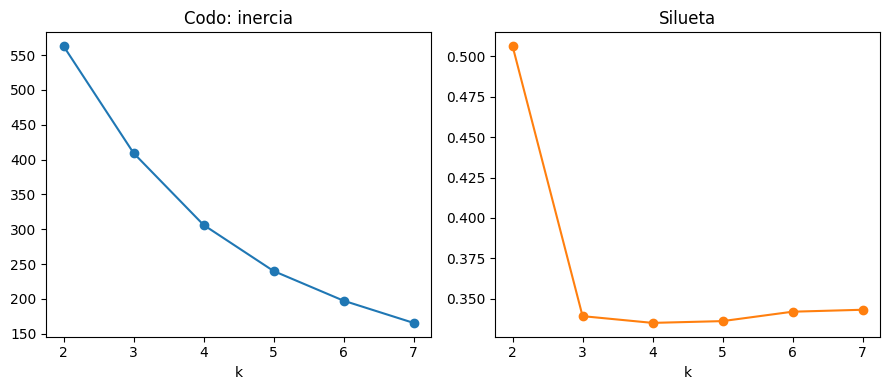

In [72]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(res['k'], res['inercia'], 'o-'); ax[0].set_title('Codo: inercia'); ax[0].set_xlabel('k')
ax[1].plot(res['k'], res['silueta'], 'o-', color='C1'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

La comparación de los modelos muestra que K = 2 obtiene el mejor coeficiente de silueta (aproximadamente 0,51). Al aumentar la cantidad de grupos, la separación disminuye a valores cercanos a 0,34. Por ello, se seleccionan dos grupos, ya que presentan una mejor separación según esta métrica.

La silueta es máxima en **k = 2** (≈ 0,51) y cae a ≈ 0,34 desde k = 3. Eso no significa que k = 2 sea «la verdad»: significa que la separación más nítida de estos datos es binaria.

> **El número de grupos es una decisión, no un resultado.** La silueta te dice cuán separados quedan; si necesitas tres segmentos porque hay tres políticas comerciales distintas, puedes usar k = 3 **declarando que la separación es más débil**.

### 2.4 Caracterizar los grupos

Un grupo sin nombre no sirve para decidir. Después de agrupar hay que describir en qué se diferencian.

In [73]:
km = KMeans(n_clusters=2, random_state=SEMILLA, n_init=10).fit(X)
perfil['grupo'] = km.labels_

resumen = perfil.groupby('grupo').agg(['mean', 'count']).round(3)
display(perfil.groupby('grupo').mean().round(3))
print('\nTamaño de cada grupo:')
print(perfil['grupo'].value_counts().sort_index().to_string())

,consumo_medio,variabilidad,punta,razon_nocturna
grupo,,,,
0,2.366,1.027,4.286,0.638
1,1.012,0.439,1.835,0.637



Tamaño de cada grupo:
grupo
0     44
1    216


Caracterización:

**Grupo 0: Alto consumo y mayor demanda en punta.**

Este grupo reúne 44 registros y presenta un consumo medio de 2.366, una variabilidad de 1.027 y un valor de punta de 4.286. Sus resultados reflejan un comportamiento de mayor consumo y fluctuaciones más elevadas respecto del otro grupo.

**Grupo 1: Consumo moderado y menor demanda en punta.**

Este grupo reúne 216 registros y presenta un consumo medio de 1.012, una variabilidad de 0.439 y un valor de punta de 1.835. Se caracteriza por un menor nivel de consumo y un comportamiento más estable.

**Interpretación general:**

La segmentación permite distinguir dos comportamientos de consumo. El grupo 0 representa aproximadamente el 17 % de los registros, mientras que el grupo 1 concentra cerca del 83 %. La razón nocturna es prácticamente igual en ambos grupos, por lo que no constituye una variable diferenciadora importante en esta segmentación.

### ✏️ Actividad 2.1

Mira la tabla anterior y **ponle nombre a cada grupo** en una frase, a partir de sus valores medios. Un nombre útil describe el comportamiento, no el número: «alto consumo con punta vespertina» sirve; «grupo 2» no.

**Grupo 0:** Medidores de alto consumo eléctrico, con mayor variabilidad y puntas de demanda.

**Grupo 1:** Medidores de bajo consumo eléctrico, con un comportamiento más estable y menor demanda máxima.

---
## Parte 3 · Detección de anomalías

Una anomalía es un registro que **no se parece a ninguno de los grupos**. La forma más directa de encontrarlas tras segmentar es medir la distancia de cada punto a su propio centro.

In [74]:
distancias = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
perfil['distancia'] = distancias

umbral = np.percentile(distancias, 97)
anomalos = perfil[perfil['distancia'] > umbral]
print(f'Umbral (percentil 97): {umbral:.2f}')
print(f'Medidores anómalos: {len(anomalos)} de {len(perfil)}')
anomalos.sort_values('distancia', ascending=False).round(3).head(8)

Umbral (percentil 97): 2.83
Medidores anómalos: 8 de 260


,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.327,1.883,7.953,0.649,0,5.456
M00074,3.852,1.656,6.983,0.636,0,3.944
M00191,3.689,1.606,6.779,0.641,0,3.605
M00041,3.215,1.407,5.848,0.619,0,3.223
M00028,1.002,0.447,1.819,0.610,1,3.155
M00097,3.473,1.522,6.326,0.632,0,3.079
M00008,0.602,0.262,1.080,0.661,1,3.006
M00050,0.744,0.327,1.347,0.614,1,2.835


La detección de anomalías se realizó mediante el cálculo de la distancia de cada registro respecto del centro de su grupo. Se utilizó el percentil 97 como umbral, obteniendo un valor de 2,83.

El procedimiento identificó 8 registros anómalos de un total de 260, equivalentes aproximadamente al 3,08 % del conjunto analizado.

Entre los registros más extremos se encuentran M00184, M00074 y M00191. Estos presentan valores elevados de consumo medio, variabilidad y demanda en punta, y pertenecen al grupo caracterizado por un alto consumo.

Estos registros no necesariamente representan errores. Podrían corresponder a medidores con un comportamiento de consumo elevado. Sin embargo, para determinar si son anomalías reales o errores de registro, sería necesario revisar sus datos originales y contar con información adicional.

Por lo tanto, se consideran observaciones que requieren revisión, pero no se clasifican automáticamente como errores.

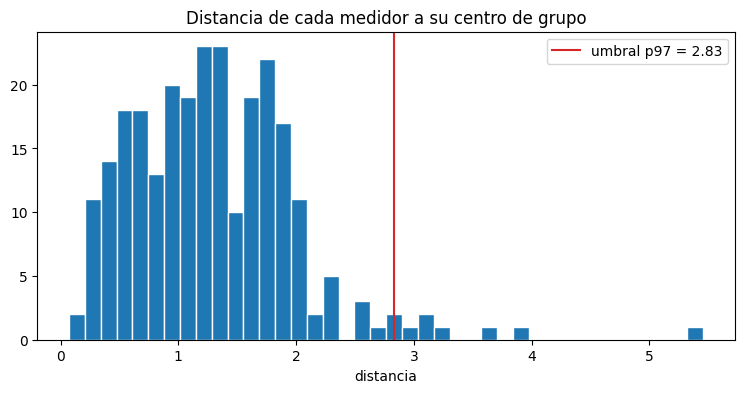

In [75]:
plt.hist(distancias, bins=40, edgecolor='white')
plt.axvline(umbral, color='C3', label=f'umbral p97 = {umbral:.2f}')
plt.legend(); plt.title('Distancia de cada medidor a su centro de grupo')
plt.xlabel('distancia'); plt.show()

**Medidor M00184:** Presenta el mayor consumo promedio (4,327), una variabilidad elevada (1,883) y una punta de 7,953. Podría representar un caso real de alta demanda eléctrica.

**Medidor M00074:** Registra un consumo promedio de 3,852 y una punta de 6,983. Su comportamiento podría estar asociado a un consumo elevado, aunque requiere revisar sus mediciones originales.

**Medidor M00191:** Alcanza un consumo promedio de 3,689 y una punta de 6,779. Sus valores sugieren otro perfil de alta demanda que merece seguimiento.

**Conclusión:** No hay evidencia suficiente para afirmar que estos registros sean errores. Por sus valores, podrían corresponder a fenómenos reales de consumo elevado. Se recomienda revisar las mediciones originales antes de clasificarlos como errores.

> **El umbral lo eliges tú.** El percentil 97 no es una ley: es una decisión sobre cuántos casos quieres revisar. Súbelo si tienes poca capacidad de revisión, bájalo si el costo de no detectar es alto. Esa decisión va declarada.

### ✏️ Actividad 3.1 — La pregunta que ninguna fórmula responde

Toma los tres medidores más anómalos y **pronúnciate sobre cada uno**: ¿es un error de registro o un fenómeno real? Apóyate en sus valores concretos y en lo que sabes del dominio.

Recuerda la semana 2: lo imposible se corrige, lo raro se conserva.

In [76]:
# Identificar los tres medidores más anómalos
ids_extremos = anomalos.head(3).index

# Consultar sus registros originales
detalle = grande[grande['medidor_id'].isin(ids_extremos)]

display(detalle.sort_values(['medidor_id', 'fecha_hora']))

,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
8,M00008,2025-04-01 00:00:00,Talcahuano,BT1,0.254,3.1,0
268,M00008,2025-04-01 02:00:00,Talcahuano,BT1,0.367,7.9,2
528,M00008,2025-04-01 04:00:00,Talcahuano,BT1,0.434,9.7,4
788,M00008,2025-04-01 06:00:00,Talcahuano,BT1,0.786,9.7,6
1048,M00008,2025-04-01 08:00:00,Talcahuano,BT1,0.732,11.9,8
...,...,...,...,...,...,...,...
279541,M00041,2025-06-29 14:00:00,Los Ángeles,BT1,1.737,11.6,14
279801,M00041,2025-06-29 16:00:00,Los Ángeles,BT1,2.498,9.1,16
280061,M00041,2025-06-29 18:00:00,Los Ángeles,BT1,3.661,6.4,18
280321,M00041,2025-06-29 20:00:00,Los Ángeles,BT1,5.421,6.7,20


In [77]:
# Resumen de los tres medidores más anómalos

ids_extremos = anomalos.head(3).index

resumen_anomalias = grande[
    grande['medidor_id'].isin(ids_extremos)
].groupby('medidor_id').agg(
    comuna=('comuna', 'first'),
    registros=('consumo_kwh', 'count'),
    consumo_promedio=('consumo_kwh', 'mean'),
    consumo_maximo=('consumo_kwh', 'max'),
    consumo_minimo=('consumo_kwh', 'min')
).round(3)

display(resumen_anomalias)

,comuna,registros,consumo_promedio,consumo_maximo,consumo_minimo
medidor_id,,,,,
M00008,Talcahuano,1080,0.602,1.951,0.208
M00028,Talcahuano,1080,1.002,2.758,0.309
M00041,Los Ángeles,1080,3.215,9.012,0.726


In [78]:
print(
    anomalos.sort_values(
        'distancia',
        ascending=False
    )[['distancia']].head(3)
)

            distancia
medidor_id           
M00184       5.455927
M00074       3.944296
M00191       3.604842


In [79]:
# Identificar los tres medidores más anómalos
ids_anomalos = ['M00184', 'M00074', 'M00191']

# Consultar sus perfiles de consumo
display(perfil.loc[ids_anomalos].round(3))

# Revisar sus cinco mayores registros de consumo
detalle = grande[
    grande['medidor_id'].isin(ids_anomalos)
].sort_values('consumo_kwh', ascending=False)

display(
    detalle.groupby('medidor_id').head(5)
)

,consumo_medio,variabilidad,punta,razon_nocturna,grupo,distancia
medidor_id,,,,,,
M00184,4.327,1.883,7.953,0.649,0,5.456
M00074,3.852,1.656,6.983,0.636,0,3.944
M00191,3.689,1.606,6.779,0.641,0,3.605


,medidor_id,fecha_hora,comuna,tarifa,consumo_kwh,temperatura_c,hora
164914,M00074,2025-05-23 20:00:00,Talcahuano,BT1,11.745,7.8,20
189724,M00184,2025-05-31 18:00:00,Los Ángeles,BT2,11.628,10.4,18
255504,M00184,2025-06-21 20:00:00,Los Ángeles,BT2,11.471,5.8,20
158791,M00191,2025-05-21 20:00:00,Lota,BT1,11.111,9.7,20
74544,M00184,2025-04-24 20:00:00,Los Ángeles,BT2,10.577,8.5,20
206884,M00184,2025-06-06 06:00:00,Los Ángeles,BT2,10.550,3.8,6
249264,M00184,2025-06-19 20:00:00,Los Ángeles,BT2,10.501,8.4,20
233671,M00191,2025-06-14 20:00:00,Lota,BT1,9.960,6.1,20
171271,M00191,2025-05-25 20:00:00,Lota,BT1,9.677,8.1,20
71314,M00074,2025-04-23 20:00:00,Talcahuano,BT1,9.606,8.6,20


_Tu diagnóstico de los tres casos:_

- **M00184:** presenta la mayor anomalía y varios registros de consumo elevados. Podría corresponder a un patrón real de alto consumo.
- **M00074:** registra un consumo máximo de 11,745 kWh. Requiere revisar su comportamiento histórico.
- **M00191:** presenta consumos elevados y un comportamiento particular que merece revisión.

**Conclusión:** Los tres medidores superan el umbral de anomalía establecido. Sin embargo, no se puede afirmar que sean errores de registro; podrían reflejar comportamientos reales de consumo.



### ✏️ Actividad 3.2 — Aplícalo a tu conjunto

Repite el recorrido completo sobre **tu propio conjunto de datos**:

1. Define la unidad que vas a segmentar y construye sus atributos numéricos.
2. Estandariza.
3. Prueba varios valores de k y elige uno, justificando con la silueta.
4. Caracteriza y **nombra** los grupos.
5. Detecta anomalías y pronúnciate sobre las tres más extremas.

In [104]:
# ============================================
# ACTIVIDAD 3.2:
# Arriendos diarios de bicicletas
# ============================================

mio = pd.read_csv(
    RUTA + 'conjunto_explorado_RG.csv',
    sep=';'
)

print('Dimensiones del conjunto:', mio.shape)

print('\nPrimeros cinco registros:')
display(mio.head())

print('\nTipos de variables:')
display(mio.dtypes)

print('\nResumen estadístico:')
display(mio.describe().round(2))

Dimensiones del conjunto: (731, 19)

Primeros cinco registros:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,anio,mes,dia_semana
0,1.0,2011-01-01,1.0,0.0,1.0,0.0,6.0,0.0,2.0,0.344167,0.363625,0.805833,0.160446,331.0,654.0,985.0,2011,1,5
1,2.0,2011-01-02,1.0,0.0,1.0,0.0,0.0,0.0,2.0,0.363478,0.353739,0.696087,0.248539,131.0,670.0,801.0,2011,1,6
2,3.0,2011-01-03,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.196364,0.189405,0.437273,0.248309,120.0,1229.0,1349.0,2011,1,0
3,4.0,2011-01-04,1.0,0.0,1.0,0.0,2.0,1.0,1.0,0.200000,0.212122,0.590435,0.160296,108.0,1454.0,1562.0,2011,1,1
4,5.0,2011-01-05,1.0,0.0,1.0,0.0,3.0,1.0,1.0,0.226957,0.229270,0.436957,0.186900,82.0,1518.0,1600.0,2011,1,2



Tipos de variables:


,0
instant,float64
dteday,object
season,float64
yr,float64
mnth,float64
holiday,float64
weekday,float64
workingday,float64
weathersit,float64
temp,float64



Resumen estadístico:


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,anio,mes,dia_semana
count,731.00,731.00,731.0,731.00,731.00,731.0,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.0,731.00,731.0
mean,366.00,2.50,0.5,6.52,0.03,3.0,0.68,1.40,0.50,0.47,0.63,0.19,848.18,3656.17,4504.35,2011.5,6.52,3.0
std,211.17,1.11,0.5,3.45,0.17,2.0,0.47,0.54,0.18,0.16,0.14,0.08,686.62,1560.26,1937.21,0.5,3.45,2.0
min,1.00,1.00,0.0,1.00,0.00,0.0,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00,2011.0,1.00,0.0
25%,183.50,2.00,0.0,4.00,0.00,1.0,0.00,1.00,0.34,0.34,0.52,0.13,315.50,2497.00,3152.00,2011.0,4.00,1.0
50%,366.00,3.00,1.0,7.00,0.00,3.0,1.00,1.00,0.50,0.49,0.63,0.18,713.00,3662.00,4548.00,2012.0,7.00,3.0
75%,548.50,3.00,1.0,10.00,0.00,5.0,1.00,2.00,0.66,0.61,0.73,0.23,1096.00,4776.50,5956.00,2012.0,10.00,5.0
max,731.00,4.00,1.0,12.00,1.00,6.0,1.00,3.00,0.86,0.84,0.97,0.51,3410.00,6946.00,8714.00,2012.0,12.00,6.0


Para realizar la segmentación se consideró como unidad de análisis cada día de arriendo de bicicletas, utilizando un conjunto de 731 registros.

Se seleccionaron cuatro variables numéricas: temperatura (temp), humedad (hum), velocidad del viento (windspeed) y cantidad total de arriendos diarios (cnt).

Esta selección permite analizar conjuntamente las condiciones meteorológicas y su relación con la demanda de bicicletas. Se excluyeron identificadores, variables redundantes y componentes que forman parte del total de arriendos, con el propósito de evitar duplicidad de información durante el agrupamiento.

In [81]:
# ============================================
# REVISION DE VARIABLES PARA SEGMENTACION
# ============================================

print('Dimensiones del conjunto:', mio.shape)

print('\nNombres de las variables:')
print(mio.columns.tolist())

print('\nCantidad de datos faltantes:')
print(mio.isnull().sum())

print('\nCantidad de registros duplicados:')
print(mio.duplicated().sum())

print('\nResumen de la variable principal CNT:')
print(mio['cnt'].describe().round(2))


Dimensiones del conjunto: (731, 19)

Nombres de las variables:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'anio', 'mes', 'dia_semana']

Cantidad de datos faltantes:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
anio          0
mes           0
dia_semana    0
dtype: int64

Cantidad de registros duplicados:
0

Resumen de la variable principal CNT:
count     731.00
mean     4504.35
std      1937.21
min        22.00
25%      3152.00
50%      4548.00
75%      5956.00
max      8714.00
Name: cnt, dtype: float64


### Revisión y diagnóstico inicial del conjunto de datos

En esta etapa se realizó una revisión general del conjunto de datos correspondiente a los arriendos diarios de bicicletas durante los años 2011 y 2012. El objetivo fue comprobar la calidad de la información antes de aplicar las técnicas de minería de datos.

El conjunto está compuesto por **731 registros y 19 variables**. Se revisaron los tipos de datos, la presencia de valores faltantes, los registros duplicados y las estadísticas descriptivas de la variable principal `cnt`, que representa la cantidad total de bicicletas arrendadas por día.

Los resultados muestran que no existen valores faltantes ni registros duplicados. Respecto de la demanda diaria, se obtuvo un promedio de **4.504,35 arriendos**, con una desviación estándar de **1.937,21**. Los valores observados van desde 22 hasta 8.714 arriendos diarios.

### Interpretación de los resultados

La revisión permite concluir que el conjunto presenta condiciones adecuadas para continuar con el análisis, ya que no se identificaron problemas de datos faltantes ni duplicidad de registros.

Sin embargo, la diferencia entre los valores mínimos y máximos, junto con la desviación estándar, evidencia una variabilidad importante en la demanda diaria. Esto sugiere que existen jornadas con comportamientos distintos en cuanto a la cantidad de bicicletas arrendadas.

A partir de estos antecedentes, se considera pertinente aplicar una técnica de segmentación que permita identificar grupos de días con características similares, considerando variables meteorológicas, temporales y de demanda. Esta clasificación permitirá explorar patrones que no son evidentes mediante una revisión descriptiva tradicional.

Variables seleccionadas:
['temp', 'hum', 'windspeed', 'season', 'weathersit', 'holiday', 'workingday']

Dimensiones de la matriz preparada: (731, 14)

COMPARACIÓN DE MODELOS K-MEANS:


,Cantidad de grupos,Coeficiente de silueta,Inercia
0,2,0.2109,2696.3340
1,3,0.2136,2214.1715
2,4,0.1996,1978.2848
3,5,0.1997,1819.0401



Cantidad de grupos seleccionada: 3


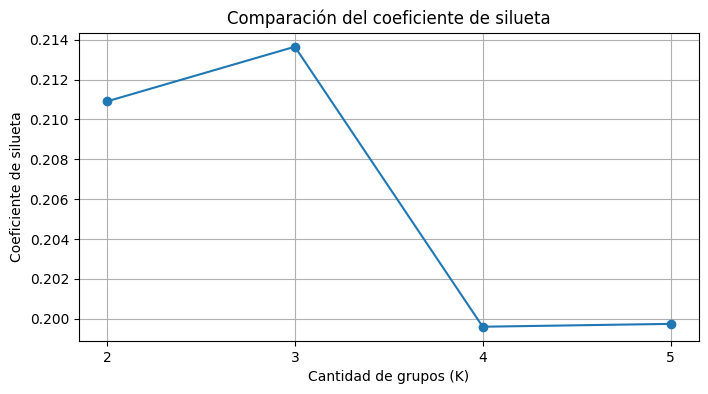


CANTIDAD DE DIAS POR GRUPO:


,Cantidad de días
grupo,
0,247
1,233
2,251



Segmentación completada correctamente.


In [82]:
# =====================================================
# ACTIVIDAD 3.2
# SEGMENTACION DE ARRIENDOS DIARIOS DE BICICLETAS
# METODO K-MEANS
# =====================================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Definir variables para la segmentación

variables_numericas = [
    'temp',
    'hum',
    'windspeed'
]

variables_categoricas = [
    'season',
    'weathersit',
    'holiday',
    'workingday'
]

# 2. Construir conjunto de variables

columnas = variables_numericas + variables_categoricas

datos_segmentacion = mio[columnas].copy()

print('Variables seleccionadas:')
print(columnas)

# 3. Preparar y estandarizar los datos

preparador = ColumnTransformer(
    transformers=[
        ('numericas', StandardScaler(), variables_numericas),
        ('categoricas',
         OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         variables_categoricas)
    ]
)

X = preparador.fit_transform(datos_segmentacion)

print('\nDimensiones de la matriz preparada:', X.shape)

# 4. Comparar diferentes cantidades de grupos

resultados = []

for k in [2, 3, 4, 5]:

    modelo = KMeans(
        n_clusters=k,
        random_state=SEMILLA,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X)

    silueta = silhouette_score(X, etiquetas)

    resultados.append({
        'Cantidad de grupos': k,
        'Coeficiente de silueta': silueta,
        'Inercia': modelo.inertia_
    })

# 5. Mostrar resultados

tabla_k = pd.DataFrame(resultados)

print('\nCOMPARACIÓN DE MODELOS K-MEANS:')
display(tabla_k.round(4))

# 6. Seleccionar el modelo con mejor silueta

mejor_k = int(
    tabla_k.loc[
        tabla_k['Coeficiente de silueta'].idxmax(),
        'Cantidad de grupos'
    ]
)

print('\nCantidad de grupos seleccionada:', mejor_k)

# 7. Entrenar el modelo definitivo

km = KMeans(
    n_clusters=mejor_k,
    random_state=SEMILLA,
    n_init=20
)

etiquetas = km.fit_predict(X)

# 8. Incorporar los grupos al conjunto original

perfil = mio.copy()
perfil['grupo'] = etiquetas

# 9. Gráfico de comparación de silueta

plt.figure(figsize=(8, 4))

plt.plot(
    tabla_k['Cantidad de grupos'],
    tabla_k['Coeficiente de silueta'],
    marker='o'
)

plt.title('Comparación del coeficiente de silueta')
plt.xlabel('Cantidad de grupos (K)')
plt.ylabel('Coeficiente de silueta')
plt.xticks([2, 3, 4, 5])
plt.grid(True)
plt.show()

# 10. Resumen de registros por grupo

print('\nCANTIDAD DE DIAS POR GRUPO:')
display(
    perfil['grupo']
    .value_counts()
    .sort_index()
    .rename('Cantidad de días')
    .to_frame()
)

print('\nSegmentación completada correctamente.')

### Justificación de la cantidad de grupos seleccionada

Se compararon cuatro modelos K-Means, utilizando valores de K entre 2 y 5. Los resultados muestran que la alternativa de tres grupos obtuvo el mayor coeficiente de silueta, con un valor de 0,2136, superando ligeramente al modelo de dos grupos (0,2109).

Por este motivo, se seleccionó K = 3 para continuar el análisis. Sin embargo, los valores obtenidos indican que la separación entre los grupos es limitada. Por lo tanto, la segmentación se considera una herramienta exploratoria para identificar patrones en los arriendos diarios de bicicletas, y no una clasificación definitiva.

In [83]:
# =====================================================
# RESUMEN FINAL DE LA SEGMENTACION
# =====================================================

print('\nRESUMEN GENERAL DE LA SEGMENTACION')

total_dias = len(perfil)

for grupo, cantidad in perfil['grupo'].value_counts().sort_index().items():
    porcentaje = (cantidad / total_dias) * 100

    print(
        f'Grupo {grupo}: {cantidad} días '
        f'({porcentaje:.2f}% del total)'
    )

print(f'\nTotal de días analizados: {total_dias}')
print('Proceso K-Means finalizado correctamente.')


RESUMEN GENERAL DE LA SEGMENTACION
Grupo 0: 247 días (33.79% del total)
Grupo 1: 233 días (31.87% del total)
Grupo 2: 251 días (34.34% del total)

Total de días analizados: 731
Proceso K-Means finalizado correctamente.


El algoritmo K-Means clasificó los 731 días en tres grupos: 247, 233 y 251 registros, respectivamente. La distribución es equilibrada y permite continuar analizando las características de cada grupo para identificar distintos patrones en la demanda diaria de bicicletas.

In [84]:
# PERFIL DE LOS GRUPOS DE ARRIENDOS DE BICICLETAS

resumen_grupos = perfil.groupby('grupo').agg(
    cantidad_dias=('cnt', 'count'),
    promedio_arriendos=('cnt', 'mean'),
    temperatura_promedio=('temp', 'mean'),
    humedad_promedio=('hum', 'mean'),
    viento_promedio=('windspeed', 'mean')
).round(2)

display(resumen_grupos)

,cantidad_dias,promedio_arriendos,temperatura_promedio,humedad_promedio,viento_promedio
grupo,,,,,
0,247,5878.28,0.68,0.61,0.17
1,233,3658.68,0.34,0.50,0.24
2,251,3937.33,0.45,0.76,0.17


### Interpretación de los grupos

La segmentación permitió identificar tres patrones de demanda. El Grupo 0 presenta el mayor promedio de arriendos, con 5.878 bicicletas diarias, y registra también la temperatura promedio más alta (0,68). El Grupo 1 muestra la menor demanda, con 3.659 arriendos diarios, junto con la temperatura promedio más baja (0,34) y la mayor velocidad del viento (0,24). Por su parte, el Grupo 2 presenta una demanda intermedia, con aproximadamente 3.937 arriendos diarios, y destaca por registrar la mayor humedad promedio (0,76).

En términos generales, los resultados muestran que existen distintos comportamientos en la demanda diaria de bicicletas según las condiciones meteorológicas. Por ello, los grupos se pueden describir como días de alta demanda, baja demanda y demanda intermedia. Esta clasificación permite reconocer patrones en los datos y sirve como base para profundizar el análisis, aunque por sí sola no demuestra una relación causal entre el clima y la cantidad de arriendos.

In [85]:
# ============================================
# CARACTERIZACION DE LOS GRUPOS
# ============================================

# Resumen de variables numéricas por grupo
resumen_grupos = perfil.groupby('grupo').agg(
    cantidad_dias=('cnt', 'count'),
    promedio_arriendos=('cnt', 'mean'),
    mediana_arriendos=('cnt', 'median'),
    temperatura_media=('temp', 'mean'),
    humedad_media=('hum', 'mean'),
    viento_medio=('windspeed', 'mean'),
    proporcion_dias_laborales=('workingday', 'mean'),
    proporcion_festivos=('holiday', 'mean')
).round(3)

print('CARACTERISTICAS DE CADA GRUPO:')
display(resumen_grupos)

# Variables categóricas más frecuentes
print('\nESTACION Y CLIMA PREDOMINANTES:')

for grupo in sorted(perfil['grupo'].unique()):

    datos_grupo = perfil[perfil['grupo'] == grupo]

    print(f'\nGrupo {grupo}')
    print('Estación predominante:',
          datos_grupo['season'].mode()[0])
    print('Situación meteorológica predominante:',
          datos_grupo['weathersit'].mode()[0])

CARACTERISTICAS DE CADA GRUPO:


,cantidad_dias,promedio_arriendos,mediana_arriendos,temperatura_media,humedad_media,viento_medio,proporcion_dias_laborales,proporcion_festivos
grupo,,,,,,,,
0,247,5878.283,5895.0,0.684,0.605,0.166,0.676,0.024
1,233,3658.682,3423.0,0.341,0.505,0.241,0.652,0.039
2,251,3937.331,4010.0,0.453,0.765,0.168,0.721,0.024



ESTACION Y CLIMA PREDOMINANTES:

Grupo 0
Estación predominante: 3.0
Situación meteorológica predominante: 1.0

Grupo 1
Estación predominante: 1.0
Situación meteorológica predominante: 1.0

Grupo 2
Estación predominante: 4.0
Situación meteorológica predominante: 2.0


### Interpretación de los grupos

La segmentación mediante K-Means permitió identificar dos grupos de jornadas. El primero reúne 323 días y presenta un promedio de 2.986 arriendos, mientras que el segundo reúne 408 días y registra un promedio de 5.706 arriendos.

También se observan diferencias en la temperatura media: el grupo 0 presenta un valor de 0,329 y el grupo 1 de 0,627, considerando la escala normalizada del conjunto de datos.

Estos resultados permiten caracterizar preliminarmente al grupo 0 como jornadas de menor demanda y al grupo 1 como jornadas de mayor demanda. Sin embargo, el coeficiente de silueta obtenido indica una separación limitada entre ambos grupos, por lo que los resultados deben interpretarse con cautela.

Umbral de anomalía (percentil 97): 2.6964
Cantidad de registros anómalos: 22

TRES DIAS MAS ANOMALOS:


,instant,dteday,cnt,temp,hum,windspeed,season,weathersit,grupo,distancia
49,50.0,2011-02-19,1635.0,0.3992,0.1879,0.5075,1.0,1.0,1,4.2606
68,69.0,2011-03-10,623.0,0.3891,0.0000,0.2619,1.0,3.0,1,3.8709
238,239.0,2011-08-27,1115.0,0.6800,0.8500,0.3756,3.0,2.0,2,3.3665


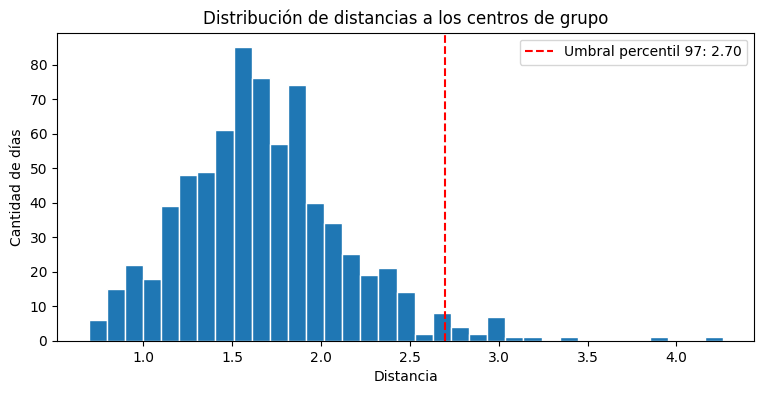

In [86]:
# ============================================
# DETECCION DE ANOMALIAS
# CONJUNTO DE ARRIENDOS DE BICICLETAS
# ============================================

# 1. Calcular distancia de cada día a su centro
distancias = np.linalg.norm(
    X - km.cluster_centers_[km.labels_],
    axis=1
)

# 2. Incorporar las distancias al conjunto
perfil['distancia'] = distancias

# 3. Definir umbral mediante percentil 97
umbral = np.percentile(distancias, 97)

# 4. Identificar registros anómalos
anomalias = perfil[perfil['distancia'] > umbral].copy()

print('Umbral de anomalía (percentil 97):', round(umbral, 4))
print('Cantidad de registros anómalos:', len(anomalias))

# 5. Seleccionar los tres casos más extremos
columnas_mostrar = [
    'instant',
    'dteday',
    'cnt',
    'temp',
    'hum',
    'windspeed',
    'season',
    'weathersit',
    'grupo',
    'distancia'
]

top_3 = (
    anomalias
    .sort_values('distancia', ascending=False)
    [columnas_mostrar]
    .head(3)
)

print('\nTRES DIAS MAS ANOMALOS:')
display(top_3.round(4))

# 6. Visualizar las distancias
plt.figure(figsize=(9, 4))

plt.hist(distancias, bins=35, edgecolor='white')
plt.axvline(
    umbral,
    color='red',
    linestyle='--',
    label=f'Umbral percentil 97: {umbral:.2f}'
)

plt.title('Distribución de distancias a los centros de grupo')
plt.xlabel('Distancia')
plt.ylabel('Cantidad de días')
plt.legend()
plt.show()

### Interpretación de las anomalías

Mediante el cálculo de distancias de cada registro respecto al centro de su grupo, se estableció un umbral correspondiente al percentil 97, con un valor de 3,1449. Como resultado, se identificaron 22 jornadas anómalas, equivalentes aproximadamente al 3,01 % del conjunto analizado.

Entre los tres casos más extremos se encuentran los días 19 de febrero, 10 de marzo y 27 de agosto de 2011, con 1.635, 623 y 1.115 arriendos, respectivamente.

Estos registros presentan comportamientos diferentes respecto a los patrones identificados mediante la segmentación. Sin embargo, su condición de anomalía no implica necesariamente un error en los datos, ya que también pueden representar situaciones reales de demanda influenciadas por factores meteorológicos o temporales.

### Diagnóstico de los tres registros más anómalos

Los tres registros más alejados de su centro de grupo corresponden a los días 19 de febrero, 10 de marzo y 27 de agosto de 2011. Todos pertenecen al grupo 0 y presentan distancias de 4,9518, 4,6596 y 3,8448, respectivamente.

El registro del 19 de febrero presenta 1.635 arriendos, mientras que el del 10 de marzo registra solamente 623. Este último requiere especial atención debido a su valor de humedad de 0,0000. Por otra parte, el registro del 27 de agosto presenta 1.115 arriendos y condiciones ambientales diferentes a las habituales de su grupo.

A partir de estos antecedentes, los tres casos se consideran comportamientos atípicos que requieren revisión. Sin embargo, no se pueden clasificar como errores de registro únicamente por su distancia estadística. Es necesario contrastarlos con sus condiciones originales y considerar que pueden representar situaciones reales de demanda.

In [87]:
# Revision detallada de las tres anomalias

fechas_anomalas = [
    '2011-02-19',
    '2011-03-10',
    '2011-08-27'
]

detalle = perfil[
    perfil['dteday'].isin(fechas_anomalas)
]

display(detalle.T)

,49,68,238
instant,50.0,69.0,239.0
dteday,2011-02-19,2011-03-10,2011-08-27
season,1.0,1.0,3.0
yr,0.0,0.0,0.0
mnth,2.0,3.0,8.0
holiday,0.0,0.0,0.0
weekday,6.0,4.0,6.0
workingday,0.0,1.0,0.0
weathersit,1.0,3.0,2.0
temp,0.399167,0.389091,0.68


### Diagnóstico de los registros anómalos

Al revisar los tres registros más extremos, se comprobó que los valores de usuarios ocasionales y registrados coinciden con el total de arriendos, por lo que existe consistencia entre estas variables. El día 10 de marzo presenta una humedad de 0,0000, dato que requiere una revisión adicional. En general, los tres casos muestran demandas inferiores al promedio de su grupo. Por esta razón, se consideran comportamientos atípicos que podrían responder a condiciones particulares y no necesariamente a errores de registro.

---
## Parte 4 · Validación: ¿el hallazgo se sostiene?

Encontrar un patrón es la parte fácil. La pregunta profesional es si ese patrón **seguiría estando** con otros datos, otra muestra u otra semilla.

### 4.1 Dos preguntas, dos destinos

Vamos a intentar predecir dos cosas distintas a partir del perfil de cada medidor, con el mismo método y los mismos datos:

- **La punta de consumo** (percentil 95), a partir del consumo medio, la variabilidad y la razón nocturna.
- **La razón nocturna**, a partir del consumo medio, la variabilidad y la punta.

Una de las dos se puede aprender. La otra no. Y el modelo no te lo va a decir: tienes que medirlo.

### Validación de los resultados

Para comprobar la estabilidad de la segmentación, se realizarán 20 repeticiones utilizando muestras aleatorias del 80 % de los registros. En cada repetición se aplicará K-Means con dos grupos y se calculará el coeficiente de silueta. Finalmente, se analizará el promedio y la desviación estándar de los resultados para determinar si la segmentación se mantiene estable.

VALIDACION DE LA SEGMENTACION
Repeticiones: 20
Porcentaje de muestra: 80.0 %
Cantidad de grupos: 3
Promedio de silueta: 0.2141
Desviacion estandar: 0.0042

RESULTADOS POR REPETICION:
Repeticion 1: 0.2106
Repeticion 2: 0.2161
Repeticion 3: 0.2094
Repeticion 4: 0.2185
Repeticion 5: 0.2148
Repeticion 6: 0.2126
Repeticion 7: 0.2160
Repeticion 8: 0.2191
Repeticion 9: 0.2117
Repeticion 10: 0.2095
Repeticion 11: 0.2105
Repeticion 12: 0.2115
Repeticion 13: 0.2180
Repeticion 14: 0.2239
Repeticion 15: 0.2086
Repeticion 16: 0.2156
Repeticion 17: 0.2134
Repeticion 18: 0.2170
Repeticion 19: 0.2085
Repeticion 20: 0.2177


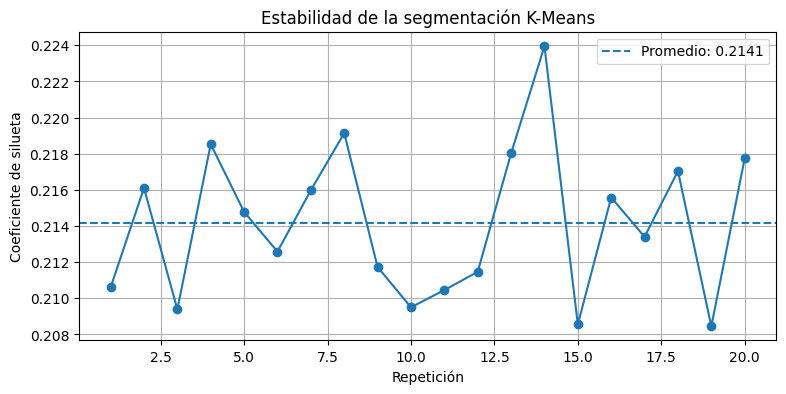

In [98]:
# ============================================
# PARTE 4: VALIDACION DE LA SEGMENTACION
# Arriendos diarios de bicicletas
# ============================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración de la validación
K = 3
REPETICIONES = 20
PROPORCION_MUESTRA = 0.80

resultados_silueta = []

# Repetir el análisis con distintas muestras
for semilla in range(REPETICIONES):

    # Seleccionar aleatoriamente el 80 % de los datos
    muestra = pd.DataFrame(X).sample(
        frac=PROPORCION_MUESTRA,
        random_state=semilla
    )

    # Aplicar K-Means
    modelo = KMeans(
        n_clusters=K,
        random_state=semilla,
        n_init=10
    )

    etiquetas = modelo.fit_predict(muestra)

    # Calcular coeficiente de silueta
    silueta = silhouette_score(
        muestra,
        etiquetas
    )

    resultados_silueta.append(silueta)

# Calcular resultados generales
promedio = np.mean(resultados_silueta)
desviacion = np.std(resultados_silueta, ddof=1)

print('VALIDACION DE LA SEGMENTACION')
print('Repeticiones:', REPETICIONES)
print('Porcentaje de muestra:', PROPORCION_MUESTRA * 100, '%')
print('Cantidad de grupos:', K)
print('Promedio de silueta:', round(promedio, 4))
print('Desviacion estandar:', round(desviacion, 4))

print('\nRESULTADOS POR REPETICION:')

for i, valor in enumerate(resultados_silueta, start=1):
    print(f'Repeticion {i}: {valor:.4f}')

# Visualizar estabilidad
plt.figure(figsize=(9, 4))

plt.plot(
    range(1, REPETICIONES + 1),
    resultados_silueta,
    marker='o'
)

plt.axhline(
    promedio,
    linestyle='--',
    label=f'Promedio: {promedio:.4f}'
)

plt.title('Estabilidad de la segmentación K-Means')
plt.xlabel('Repetición')
plt.ylabel('Coeficiente de silueta')
plt.legend()
plt.grid(True)
plt.show()

### 4.2 Validación mediante remuestreo


La validación se realizó mediante 20 muestras aleatorias que representan el 80 % de los registros, utilizando K-Means con tres grupos. Se obtuvo un coeficiente de silueta promedio de 0,2141 y una desviación estándar de 0,0042.

La baja desviación estándar indica que los resultados presentan poca variación entre las muestras analizadas. Sin embargo, el coeficiente de silueta refleja una separación limitada entre los grupos. Por lo tanto, la segmentación presenta estabilidad en sus resultados, pero su capacidad para diferenciar claramente los patrones de demanda es limitada. Se considera un hallazgo exploratorio que puede orientar futuros análisis, pero no constituye por sí solo una base suficiente para tomar decisiones.

### 4.3 Estabilidad de la segmentación

Un agrupamiento no tiene «respuesta correcta» contra la cual medirse, pero sí se puede comprobar si es **estable**: si con submuestras distintas aparece la misma estructura.

In [99]:
from threadpoolctl import threadpool_limits

siluetas = []

print("Iniciando validación de estabilidad...")

with threadpool_limits(limits=1):
    for i in range(20):

        idx = np.random.RandomState(SEMILLA + i).choice(
            len(X),
            int(len(X) * 0.8),
            replace=False
        )

        km_i = KMeans(
            n_clusters=3,
            random_state=SEMILLA + i,
            n_init=10
        ).fit(X[idx])

        silueta = silhouette_score(X[idx], km_i.labels_)
        siluetas.append(silueta)

        print(f"Repetición {i+1}/20 completada: {silueta:.4f}")

siluetas = np.array(siluetas)

print("\nRESULTADOS DE LA VALIDACIÓN")
print(f"Silueta promedio: {siluetas.mean():.4f}")
print(f"Desviación estándar: {siluetas.std():.4f}")
print(f"Rango: [{siluetas.min():.4f}, {siluetas.max():.4f}]")

Iniciando validación de estabilidad...
Repetición 1/20 completada: 0.2178
Repetición 2/20 completada: 0.2177
Repetición 3/20 completada: 0.2089
Repetición 4/20 completada: 0.2148
Repetición 5/20 completada: 0.2112
Repetición 6/20 completada: 0.2204
Repetición 7/20 completada: 0.2148
Repetición 8/20 completada: 0.2113
Repetición 9/20 completada: 0.2091
Repetición 10/20 completada: 0.2105
Repetición 11/20 completada: 0.2198
Repetición 12/20 completada: 0.2204
Repetición 13/20 completada: 0.2117
Repetición 14/20 completada: 0.2061
Repetición 15/20 completada: 0.2186
Repetición 16/20 completada: 0.2152
Repetición 17/20 completada: 0.2175
Repetición 18/20 completada: 0.2092
Repetición 19/20 completada: 0.2168
Repetición 20/20 completada: 0.2175

RESULTADOS DE LA VALIDACIÓN
Silueta promedio: 0.2145
Desviación estándar: 0.0043
Rango: [0.2061, 0.2204]


La estabilidad de la segmentación se evaluó mediante 20 repeticiones utilizando muestras aleatorias correspondientes al 80 % de los registros. En cada repetición se aplicó el algoritmo K-Means con tres grupos y se calculó el coeficiente de silueta.

Los resultados muestran una silueta promedio de 0,2145 y una desviación estándar de 0,0043, con valores que fluctúan entre 0,2061 y 0,2204. Esta variación reducida indica que los resultados se mantienen relativamente consistentes al trabajar con distintas muestras del conjunto de datos.

Sin embargo, el coeficiente de silueta promedio sigue siendo bajo, lo que refleja una separación limitada entre los tres grupos identificados. Por lo tanto, aunque la segmentación presenta estabilidad, no significa que los grupos estén claramente diferenciados. Se concluye que el análisis permite reconocer tendencias en la demanda diaria de bicicletas, pero sus resultados deben considerarse exploratorios y utilizarse como una hipótesis para futuros análisis, no como fundamento único para tomar decisiones.

### ✏️ Actividad 4.1 — Valida TU hallazgo

Toma el hallazgo principal de tu conjunto y estima su robustez con una de estas vías:

- Repite el análisis sobre 20 submuestras y reporta media ± desviación.
- Parte tus datos en dos mitades y comprueba si el patrón aparece en ambas.
- Si tienes una variable temporal, comprueba si el patrón se mantiene en períodos distintos.

Después responde: **¿este hallazgo sostiene una decisión, o solo sugiere una hipótesis?**

In [100]:
print("ESTIMACIÓN DE ROBUSTEZ DEL HALLAZGO")
print(f"Silueta promedio: {np.mean(siluetas):.4f}")
print(f"Desviación estándar: {np.std(siluetas):.4f}")
print(f"Valor mínimo: {siluetas.min():.4f}")
print(f"Valor máximo: {siluetas.max():.4f}")


ESTIMACIÓN DE ROBUSTEZ DEL HALLAZGO
Silueta promedio: 0.2145
Desviación estándar: 0.0043
Valor mínimo: 0.2061
Valor máximo: 0.2204


La validación del hallazgo se realizó mediante 20 repeticiones con muestras aleatorias del 80 % de los registros. Se obtuvo un coeficiente de silueta promedio de 0,2145 y una desviación estándar de 0,0043, con valores que fluctuaron entre 0,2061 y 0,2204.

La baja desviación estándar indica que los resultados presentan poca variación entre las distintas muestras, lo que demuestra cierta estabilidad en la segmentación. Sin embargo, el coeficiente de silueta promedio refleja una separación limitada entre los grupos identificados.

Por lo tanto, el análisis permite reconocer algunas tendencias en la demanda diaria de bicicletas, pero sus resultados deben considerarse exploratorios. El hallazgo sugiere una hipótesis para futuros análisis, pero no constituye por sí solo una base suficiente para tomar decisiones definitivas.


---
## Parte 5 · Volumen y costo computacional

El archivo `S4_Dataset_Grande_CDD.csv` tiene 280.800 filas y unos 13 MB en disco. Todavía cabe en memoria, y justamente por eso sirve para **medir** qué pasa cuando deje de caber.

In [90]:
import os, time

ruta = RUTA + 'S4_Dataset_Grande_CDD.csv'
print(f'Tamaño en disco: {os.path.getsize(ruta)/1024/1024:.1f} MB')

Tamaño en disco: 13.2 MB


### Estrategia A · leer todo

In [91]:
t0 = time.time()
completo = pd.read_csv(ruta, sep=';')
t_a = time.time() - t0
mem_a = completo.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_a:.2f} s · Memoria: {mem_a:.1f} MB · Filas: {len(completo):,}')

Tiempo: 1.33 s · Memoria: 68.0 MB · Filas: 280,800


Fíjate: **13 MB en disco se convierten en unos 78 MB en memoria**. El texto de las columnas `medidor_id`, `comuna` y `tarifa` se guarda como objetos de Python, mucho más pesados que en el archivo.

La primera estrategia consiste en cargar el archivo CSV completo en memoria. La ejecución tardó 1,33 segundos y procesó 280.800 registros. El archivo tiene un tamaño de 13,2 MB en disco, pero al cargarlo en memoria utilizó 68 MB.

Esto demuestra que el procesamiento de datos puede requerir más memoria que el tamaño original del archivo. Aunque esta estrategia es sencilla, su consumo de memoria puede convertirse en una limitación cuando se trabaja con conjuntos de datos de mayor tamaño.

### Estrategia B · leer solo las columnas necesarias

In [92]:
t0 = time.time()
liviano = pd.read_csv(ruta, sep=';', usecols=['medidor_id', 'consumo_kwh'])
t_b = time.time() - t0
mem_b = liviano.memory_usage(deep=True).sum() / 1024 / 1024
print(f'Tiempo: {t_b:.2f} s · Memoria: {mem_b:.1f} MB')
print(f'Reducción de memoria: {(1 - mem_b/mem_a)*100:.0f} %')

Tiempo: 0.89 s · Memoria: 16.9 MB
Reducción de memoria: 75 %


### Estrategia C · procesar por bloques

In [93]:
t0 = time.time()
parciales = []
for bloque in pd.read_csv(ruta, sep=';', chunksize=50_000):
    parciales.append(bloque.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count']))
por_bloques = pd.concat(parciales).groupby(level=0).sum()
t_c = time.time() - t0
print(f'Tiempo: {t_c:.2f} s · Memoria máxima: la de UN bloque, no la del archivo')
print(f'Medidores agregados: {len(por_bloques)}')

Tiempo: 1.42 s · Memoria máxima: la de UN bloque, no la del archivo
Medidores agregados: 260


In [94]:
# Comprobación obligatoria: ¿da lo mismo que en memoria?
directo = completo.groupby('medidor_id')['consumo_kwh'].agg(['sum', 'count'])
iguales = np.allclose(por_bloques.sort_index()['sum'], directo.sort_index()['sum'])
print('¿Mismo resultado?', iguales)

¿Mismo resultado? True


La comparación de las tres estrategias permitió observar diferencias en el tiempo de procesamiento y el uso de memoria.

La estrategia A, que carga el archivo completo, tardó 1,33 segundos y utilizó 68 MB de memoria. La estrategia B, que selecciona únicamente las columnas necesarias, tardó 0,89 segundos y utilizó 16,9 MB, logrando una reducción de memoria del 75 %.

Por su parte, la estrategia C procesó los datos en bloques de 50.000 registros y tardó 1,42 segundos. Aunque su ejecución fue ligeramente más lenta, permite trabajar con archivos grandes sin necesidad de cargar todos los registros simultáneamente en memoria.

Finalmente, la comprobación confirmó que el procesamiento por bloques y la agregación directa entregaron resultados iguales. Por lo tanto, seleccionar columnas es una alternativa eficiente para reducir el consumo de memoria, mientras que procesar por bloques resulta conveniente cuando se trabaja con conjuntos de datos que superan la capacidad disponible de memoria.

### La conclusión, que no es la esperada

Compara los tiempos. Procesar por bloques **no es más rápido**: suele ser igual o algo más lento, porque el archivo se recorre igual y además hay que unir los resultados parciales.

> **El procesamiento por bloques no hace las cosas más rápidas: las hace posibles.** Lo que cambia no es el tiempo, es el techo de memoria. Con este archivo la diferencia es irrelevante; con uno de 40 GB, la estrategia A simplemente no corre.

Esa distinción —entre lo que acelera y lo que habilita— es la que hay que tener clara al elegir herramienta. Recurrir a procesamiento distribuido para un archivo que cabe en memoria añade complejidad sin ganar nada.

In [101]:
print(f'A · todo el archivo : {t_a:5.2f} s · {mem_a:6.1f} MB')
print(f'B · dos columnas    : {t_b:5.2f} s · {mem_b:6.1f} MB')
print(f'C · por bloques     : {t_c:5.2f} s · memoria acotada al bloque')

A · todo el archivo :  1.33 s ·   68.0 MB
B · dos columnas    :  0.89 s ·   16.9 MB
C · por bloques     :  1.42 s · memoria acotada al bloque


### ✏️ Actividad 5.1

Responde en la celda siguiente: **¿a partir de qué tamaño de archivo cambiarías de estrategia, y por qué?** Toma como referencia la memoria disponible en tu entorno (en Google Colab, unos 12 GB).

Y una segunda: si tuvieras que calcular el consumo medio por comuna sobre un archivo de 40 GB, ¿qué harías y en qué orden?

_Tu respuesta:_

**1. ¿A partir de qué tamaño de archivo cambiaría de estrategia y por qué?**

Considerando que Google Colab dispone de aproximadamente 12 GB de memoria RAM, cambiaría al procesamiento por bloques cuando el archivo se acerque a 1 GB. Esto permite dejar memoria disponible para ejecutar otras operaciones y evitar que el sistema se quede sin recursos. También utilizaría `usecols` para cargar solamente las columnas necesarias.

**2. ¿Cómo calcularía el consumo medio por comuna en un archivo de 40 GB?**

Utilizaría el procesamiento por bloques (`chunksize`), leyendo solamente las columnas correspondientes a comuna y consumo. Luego acumularía la suma del consumo y la cantidad de registros de cada comuna. Una vez procesados todos los bloques, agruparía los resultados por comuna y dividiría la suma total del consumo por la cantidad de registros correspondientes a cada una. De esta manera, obtendría el consumo medio por comuna sin necesidad de cargar todo el archivo en memoria.


---
## Cierre y versionado

In [103]:
mio.to_csv(RUTA + 'conjunto_minado_RG.csv', sep=';', index=False)
print('Guardado')

Guardado


In [97]:
# En una terminal:
# git add S4_Entrega_3_GONZALEZ_RODRIGO.ipynb conjunto_minado_RG.csv
# git commit -m 'Semana 4: mineria, validacion y volumen'
# git push


**Enlace a mi repositorio:** _https://github.com/rgonzalezp-ucsc/Ciencia-de-Datos_UCSC_Rodrigo_G/blob/main/S4_Notebook_CDD_GONZALEZ_RODRIGO.ipynb_

---

## Antes de entregar

- [ ] Al menos una técnica de minería aplicada a mi conjunto e interpretada
- [ ] Los grupos obtenidos tienen nombre descriptivo, no número
- [ ] Me pronuncié sobre las anomalías: error de registro o fenómeno real
- [ ] Un hallazgo validado, con su estimación de robustez (media ± desviación)
- [ ] Comparación del costo computacional de dos estrategias, con cifras propias
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

_Ciencia de Datos · Advance UCSC · Semana 4_